In [1]:
import pandas as pd
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.cluster import DBSCAN




In [2]:

stocks_sect = pd.read_parquet("data_processed/stocks_sect.parquet")
stocks_sect.head()
print(stocks_sect.shape)
stocks_sect.columns



(9867430, 21)


Index(['Date', 'Weekday', 'Open', 'High', 'Low', 'Close', 'Adj Close',
       'Volume', 'Symbol', 'Volatility', 'ticker', 'Sector', 'Return',
       'SectorVolume', 'Weight', 'RollingVol20', 'WeightedVol20',
       'RollingVol60', 'WeightedVol60', 'RollingVol120', 'WeightedVol120'],
      dtype='object')

In [3]:

etfs_sect = pd.read_parquet("data_processed/etfs_clean.parquet")
etfs_sect.head()
print(etfs_sect.shape)
etfs_sect.columns


(3920498, 11)


Index(['Date', 'Weekday', 'Open', 'High', 'Low', 'Close', 'Adj Close',
       'Volume', 'Symbol', 'Volatility', 'ticker'],
      dtype='object')

In [17]:
# Count how many rows have Sector = NaN
missing_sector_count = stocks_sect["Sector"].isna().sum()

missing_sector_count


np.int64(0)

In [18]:
vol_cols = ["RollingVol20", "RollingVol60", "RollingVol120"]


In [19]:
sector_vol = (
    stocks_sect
    .groupby("Sector")[vol_cols]
    .agg(["mean", "median", "std"])
)

sector_vol.head()


RollingVol20                     RollingVol60  \
                               mean    median       std         mean   
Sector                                                                 
Basic Materials            0.030414  0.025260  0.020564     0.031162   
Communication Services     0.027490  0.021099  0.022829     0.028453   
Consumer Cyclical          0.026858  0.020869  0.023500     0.027721   
Consumer Defensive         0.023664  0.017538  0.024535     0.024565   
Energy                     0.030190  0.023119  0.028719     0.031024   

                                           RollingVol120                      
                          median       std          mean    median       std  
Sector                                                                        
Basic Materials         0.026547  0.018605      0.031567  0.027138  0.017669  
Communication Services  0.022584  0.020952      0.028908  0.023302  0.020206  
Consumer Cyclical       0.022301  0.021704      0.028130  0.022916  0.021095  
Consumer Defensive      0.019085  0.023017      0.024978  0.019757  0.022459  
Energy                  0.024401  0.026625      0.031528  0.025089  0.025719

In [28]:
sector_vol.columns = [
    f"{col[0]}_{col[1]}" for col in sector_vol.columns.to_list()
]

sector_vol.head(11)


,R__,R__,R__,R__,R__,R__,R__,R__,R__
Sector,,,,,,,,,
Basic Materials,0.030414,0.025260,0.020564,0.031162,0.026547,0.018605,0.031567,0.027138,0.017669
Communication Services,0.027490,0.021099,0.022829,0.028453,0.022584,0.020952,0.028908,0.023302,0.020206
Consumer Cyclical,0.026858,0.020869,0.023500,0.027721,0.022301,0.021704,0.028130,0.022916,0.021095
Consumer Defensive,0.023664,0.017538,0.024535,0.024565,0.019085,0.023017,0.024978,0.019757,0.022459
Energy,0.030190,0.023119,0.028719,0.031024,0.024401,0.026625,0.031528,0.025089,0.025719
Financial Services,0.017592,0.012147,0.023660,0.018160,0.013086,0.022623,0.018547,0.013612,0.022285
Healthcare,0.037921,0.029506,0.032743,0.039465,0.032509,0.029909,0.040100,0.034027,0.028624
Industrials,0.027136,0.020647,0.026785,0.028032,0.022040,0.025108,0.028469,0.022649,0.024416
Real Estate,0.019696,0.013849,0.020939,0.020184,0.014367,0.019495,0.020575,0.014614,0.019010


In [21]:
sector_vol.shape


(11, 9)

In [22]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(sector_vol)

X_scaled[:5]  # just to see the first rows


array([[ 0.69516769,  0.99487305, -0.77953524,  0.65099919,  0.88438909,
        -0.89177759,  0.63904848,  0.83657611, -0.9810574 ],
       [ 0.2146056 ,  0.20739227, -0.28260379,  0.22477498,  0.2066019 ,
        -0.33485794,  0.22585579,  0.20991994, -0.35758833],
       [ 0.11079328,  0.1639202 , -0.13533182,  0.10965867,  0.15826985,
        -0.15649946,  0.10496702,  0.14693629, -0.13900175],
       [-0.41416837, -0.46638593,  0.09170387, -0.38694254, -0.39174482,
         0.15517933, -0.38486474, -0.36900062,  0.1961207 ],
       [ 0.65837656,  0.58968636,  1.00965028,  0.62930362,  0.51735411,
         1.01149843,  0.63291079,  0.50188332,  0.99729434]])

In [39]:
dbscan = DBSCAN(eps=1.3, min_samples=2)
clusters = dbscan.fit_predict(X_scaled)

clusters


array([-1,  0,  0, -1,  1, -1, -1,  1, -1,  1, -1])

In [40]:
for sector_name, label in zip(sector_vol.index, clusters):
    print(sector_name, "→", label)


Basic Materials → -1
Communication Services → 0
Consumer Cyclical → 0
Consumer Defensive → -1
Energy → 1
Financial Services → -1
Healthcare → -1
Industrials → 1
Real Estate → -1
Technology → 1
Utilities → -1


In [41]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt


In [42]:
pca = PCA(n_components=2)
coords = pca.fit_transform(X_scaled)


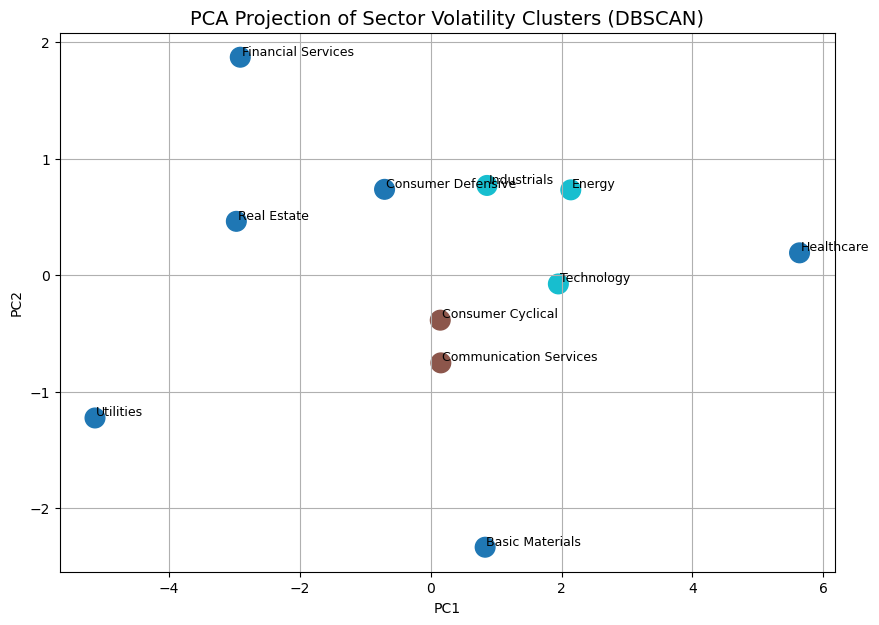

In [44]:
plt.figure(figsize=(10, 7))

# Scatter plot
plt.scatter(coords[:, 0], coords[:, 1], c=clusters, s=200, cmap="tab10")

# Add labels for each sector
for i, sector_name in enumerate(sector_vol.index):
    plt.text(coords[i, 0] + 0.02, coords[i, 1] + 0.02, sector_name, fontsize=9)

plt.title("PCA Projection of Sector Volatility Clusters (DBSCAN)", fontsize=14)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.grid(True)
plt.show()
